# Eje 5a — Modelo binomial CRR (paso a paso)

Derivados Financieros — QUANt UCEMA

El **árbol binomial de Cox–Ross–Rubinstein (CRR)** es el primer modelo de pricing que construimos “a mano”:
discretizamos el tiempo, movemos el subyacente arriba/abajo, y **retropropagamos** el valor de la opción
bajo la probabilidad riesgo-neutral.

| Notebook | Contenido |
|----------|-----------|
| **05a** (este) | CRR europea: parámetros, árbol N=3, fórmula cerrada, `Codigo.pricing` |
| **05b** | Americanas (ejercicio temprano) y convergencia a Black–Scholes |
| **06a/06b** | Fórmula de Black–Scholes y comparación bin↔BS |

Material legado (Clase 3): desglose del método + fórmula cerrada.

**Plan:**
1. Setup e idea del modelo
2. Un paso: $u$, $d$ y $q$
3. Árbol con N=3 (columna por columna)
4. Precio en el nodo 0
5. Forma cerrada europea
6. Usar `opcion_europea_bin` / `opcion_europea_bin_c`

## 1) Setup

Correr desde la raíz del repo (o con path al proyecto).

In [1]:
import math
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
for p in [ROOT, *ROOT.parents]:
    if (p / "Codigo" / "pricing").exists():
        sys.path.insert(0, str(p))
        break

from Codigo.pricing import opcion_europea_bin, opcion_europea_bin_c, opcion_europea_bs
from Codigo.utils.binomial_tree import plot_crr_tree, build_crr_lattices

pd.set_option("display.width", 120)
print("OK")

OK


## 2) Idea del modelo

En cada paso $\Delta t = T/N$ el subyacente puede subir o bajar:

$$
S \to Su \quad \text{o} \quad S \to Sd
$$

En CRR:

$$
u = e^{\sigma \sqrt{\Delta t}}, \qquad d = 1/u
$$

La probabilidad **riesgo-neutral** de subir es

$$
q = \frac{e^{(r-q_{div})\Delta t} - d}{u - d}
$$

El precio de la opción se obtiene descontando el valor esperado bajo $q$:

$$
V = e^{-r\Delta t}\big(q\, V_u + (1-q)\, V_d\big)
$$

Al vencimiento: $V_T = \max(S_T-K,0)$ (call) o $\max(K-S_T,0)$ (put).

## 3) Parámetros de trabajo (N=3 para ver el árbol)

In [2]:
tipo = "C"   # "C" call | "P" put
S = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.25
div = 0.0
pasos = 3

dt = T / pasos
tasa_forward = math.exp((r - div) * dt)
descuento = math.exp(-r * dt)
u = math.exp(sigma * math.sqrt(dt))
d = 1.0 / u
q = (tasa_forward - d) / (u - d)

print(f"dt={dt:.4f}  u={u:.6f}  d={d:.6f}  q={q:.6f}  desc={descuento:.6f}")
assert 0 < q < 1, "q fuera de (0,1): revisá parámetros / pasos"

dt=0.3333  u=1.155274  d=0.865596  q=0.521995  desc=0.983471


## 4) Precios del subyacente al vencimiento

En CRR recombinante, el nodo con $k$ subidas (y $N-k$ bajadas) vale

$$
S\, u^{k} d^{N-k} = S\, u^{2k-N}
$$

Ordenamos el vector de mayor a menor (como en el código del curso).

In [3]:
ST = np.zeros(pasos + 1)
for i in range(pasos + 1):
    # i=0 → máximo (todas subidas); i=pasos → mínimo
    ST[i] = S * (u ** (pasos - 2 * i))
print("S_T (de más alto a más bajo):", np.round(ST, 4))

S_T (de más alto a más bajo): [154.1896 115.5274  86.5596  64.8552]


## 5) Payoff en la última columna del árbol

In [4]:
V = np.zeros((pasos + 1, pasos + 1))
for i in range(pasos + 1):
    if tipo == "C":
        V[i, pasos] = max(ST[i] - K, 0.0)
    else:
        V[i, pasos] = max(K - ST[i], 0.0)

print("Matriz V (última columna = payoff):")
print(np.round(V, 4))

Matriz V (última columna = payoff):
[[ 0.      0.      0.     54.1896]
 [ 0.      0.      0.     15.5274]
 [ 0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.    ]]


## 6) Retropropagación columna por columna

Empezamos en $j=1$ (un paso antes del vencimiento) y vamos hacia $j=N$ (hoy).

In [5]:
for j in range(1, pasos + 1):
    col = pasos - j
    for i in range(pasos + 1 - j):
        V[i, col] = descuento * (q * V[i, col + 1] + (1 - q) * V[i + 1, col + 1])
    print(f"Después de j={j} (columna t={col}):")
    print(np.round(V, 4), "\n")

precio_manual = float(V[0, 0])
print(f"Precio europeo (nodo 0) = {precio_manual:.6f}")

Después de j=1 (columna t=2):
[[ 0.      0.     35.1187 54.1896]
 [ 0.      0.      7.9713 15.5274]
 [ 0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.    ]] 

Después de j=2 (columna t=1):
[[ 0.     21.7761 35.1187 54.1896]
 [ 0.      4.0922  7.9713 15.5274]
 [ 0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.    ]] 

Después de j=3 (columna t=0):
[[13.1029 21.7761 35.1187 54.1896]
 [ 0.      4.0922  7.9713 15.5274]
 [ 0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.    ]] 

Precio europeo (nodo 0) = 13.102896


## 6b) El árbol dibujado (no solo la matriz)

La matriz es correcta, pero didácticamente conviene **ver el grafo**: cada caja es un nodo
(tiempo →, más ups ↑), las aristas verdes son **up** y las rojas **down**.

Usamos `Codigo.utils.binomial_tree.plot_crr_tree` (mismo CRR que armamos a mano).

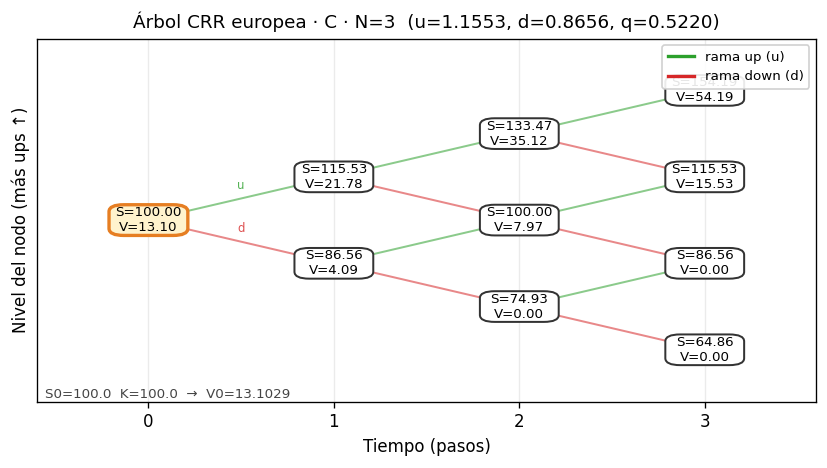

In [6]:
# Mismos parámetros que arriba (N=3)
fig, ax = plot_crr_tree(
    tipo, S, K, T, r, sigma, div, pasos,
    americana=False,
    show="both",  # "S" | "V" | "both"
)
plt.show()

# Si solo querés el subyacente (sin V):
# plot_crr_tree(tipo, S, K, T, r, sigma, div, pasos, show="S")

Con N un poco más grande el dibujo sigue siendo legible si etiquetamos solo $S$ o solo $V$:

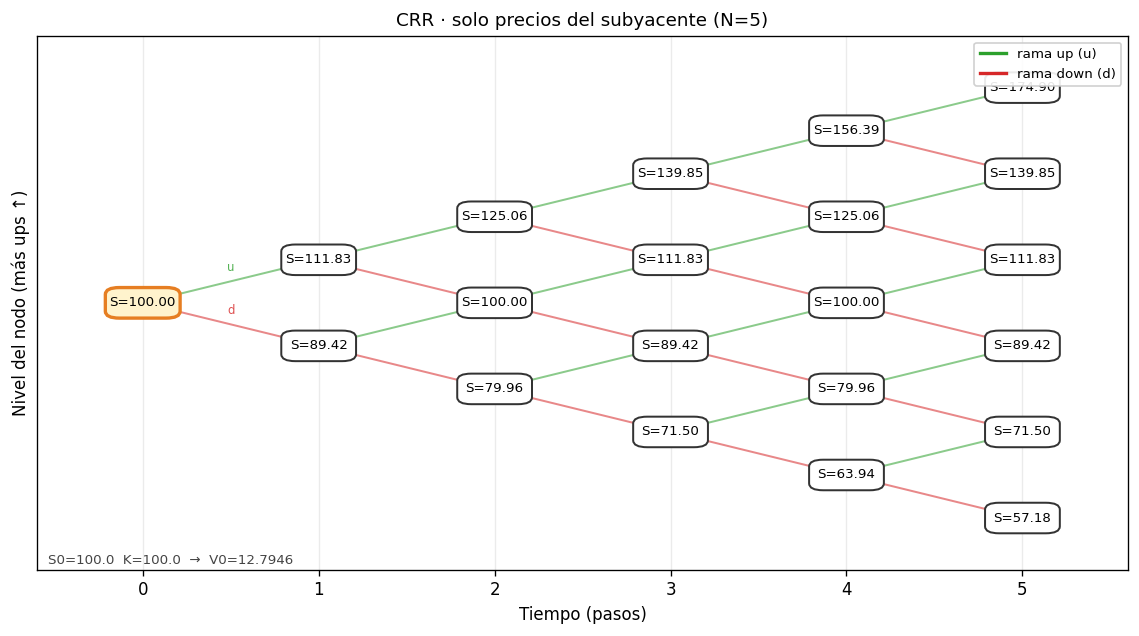

In [7]:
fig, ax = plot_crr_tree(
    tipo, S, K, T, r, sigma, div, pasos=5,
    show="S",
    title="CRR · solo precios del subyacente (N=5)",
)
plt.show()

## 7) Mismo resultado con `Codigo.pricing`

In [8]:
precio_lib = opcion_europea_bin(tipo, S, K, T, r, sigma, div, pasos)
print(f"opcion_europea_bin  = {precio_lib:.6f}")
print(f"diferencia manual   = {abs(precio_manual - precio_lib):.2e}")

opcion_europea_bin  = 13.102896
diferencia manual   = 0.00e+00


## 8) Forma cerrada (europea)

Para europeas, el árbol CRR admite una suma binomial (sin armar la matriz completa).
En el repo: `opcion_europea_bin_c`.

In [9]:
# Con N chico la forma cerrada y el árbol coinciden
p_c = opcion_europea_bin_c(tipo, S, K, T, r, sigma, div, pasos)
print(f"opcion_europea_bin_c = {p_c:.6f}")

# Con N grande se acerca a Black-Scholes (preview del eje 6)
N_big = 500
p_bin = opcion_europea_bin(tipo, S, K, T, r, sigma, div, N_big)
p_bs = opcion_europea_bs(tipo, S, K, T, r, sigma, div)
print(f"N={N_big}: bin={p_bin:.6f}  BS={p_bs:.6f}  |diff|={abs(p_bin-p_bs):.4f}")

opcion_europea_bin_c = 13.102896
N=500: bin=12.331056  BS=12.335999  |diff|=0.0049


## Resumen

- CRR: $u=e^{\sigma\sqrt{\Delta t}}$, $d=1/u$, $q$ riesgo-neutral, descuento $e^{-r\Delta t}$.
- Europea: payoff al vencimiento + retropropagación (o forma cerrada).
- `opcion_europea_bin` / `opcion_europea_bin_c` encapsulan el mismo método.
- **Ejercicio:** repetí el árbol N=3 para un **put** ATM. ¿Cambia $q$? ¿Cambia el payoff?
- **Siguiente:** **05b** — americanas y convergencia $N\to\infty$.